In [1]:
from qiskit import QuantumCircuit

qc_original = QuantumCircuit(2, 2)

qc_original.h(0)

qc_original.cx(0, 1)

qc_original.measure([0, 1], [0, 1])

print(qc_original.draw())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


Original Bell circuit results: {'00': 48, '11': 52}


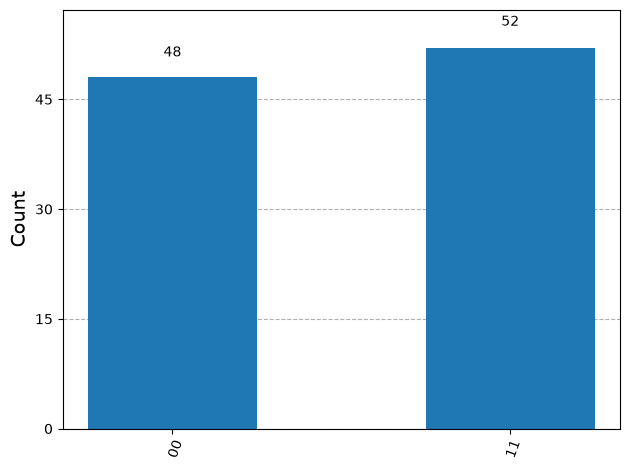

In [5]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()

job = simulator.run(qc_original, shots=100)
result = job.result()

counts_original = result.get_counts()

print("Original Bell circuit results:", counts_original)

from IPython.display import display

display(plot_histogram(counts_original))

In [3]:
# Modified Bell circuit: add one X gate
qc_modified = QuantumCircuit(2, 2)

qc_modified.h(0)
qc_modified.cx(0, 1)
qc_modified.x(1)

qc_modified.measure([0, 1], [0, 1])

print(qc_modified.draw())

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


Modified Bell circuit results: {'10': 49, '01': 51}


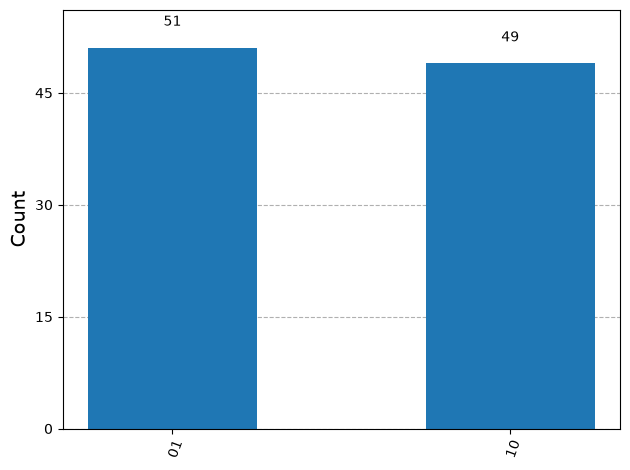

In [6]:
job_mod = simulator.run(qc_modified, shots=100)
result_mod = job_mod.result()
counts_modified = result_mod.get_counts()

print("Modified Bell circuit results:", counts_modified)

display(plot_histogram(counts_modified))

## Prediction Before Execution

I predicted that the original Bell circuit would produce `00` and `11` approximately equally. After adding an X gate to the second qubit, I expected the outcomes to change to `01` and `10`.

## Results and Comparison

**Original Bell circuit:** `00`: 49 shots, `11`: 51 shots.

**Modified Bell circuit:** `10`: 41 shots, `01`: 59 shots.

The original circuit produces outcomes where both qubits have the same value. The modified circuit produces outcomes where the qubits have opposite values.

## Conclusion

Adding one X gate to the second qubit changes the correlation pattern. The original Bell circuit produces correlated outcomes, while the modified circuit produces opposite-bit outcomes. The results agree with my prediction.